# Fuzzy Expert System (Mamdani) - HIGH-RECALL

Implements a **Mamdani** fuzzy inference system based on predictions from four base models:
- K-Nearest Neighbors
- Support Vector Machine
- Random Forest
- Multilayer Perceptron

> **System goal:** Maximise **Recall** for the Failure class while keeping the increase in false alarms at an acceptable level.

---
## 1. Library imports and model artifact loading


In [83]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    ConfusionMatrixDisplay, average_precision_score
)
import warnings
warnings.filterwarnings('ignore')

rf_art  = joblib.load('rf_artifacts.pkl')
svm_art = joblib.load('svm_artifacts.pkl')
knn_art = joblib.load('knn_artifacts.pkl')
mlp_art = joblib.load('mlp_artifacts.pkl')

p_rf  = rf_art['y_proba']
p_svm = svm_art['y_proba']
p_knn = knn_art['y_proba']
p_mlp = mlp_art['y_proba']
y_true = rf_art['y_test']

n = len(y_true)
print(f'Loaded predictions for {n} samples from the test set.')


Loaded predictions for 1500 samples from the test set.


---
## 2. Mamdani fuzzy inference system design

### Input variables (universe: [0, 1])
Each input variable (`p_rf`, `p_svm`, `p_knn`, `p_mlp`) is described by three fuzzy sets:
- **LOW** - low failure probability
- **MEDIUM** - moderate failure probability
- **HIGH** - high failure probability

### Output variable (`failure_risk`, universe: [0, 1])
Five fuzzy sets: **VERY_LOW**, **LOW**, **MEDIUM**, **HIGH**, **VERY_HIGH**

In [84]:
u = np.linspace(0, 1, 101)

p_rf_var  = ctrl.Antecedent(u, 'p_rf')
p_svm_var = ctrl.Antecedent(u, 'p_svm')
p_knn_var = ctrl.Antecedent(u, 'p_knn')
p_mlp_var = ctrl.Antecedent(u, 'p_mlp')

risk_var = ctrl.Consequent(u, 'failure_risk', defuzzify_method='centroid')

# Input membership functions
for var in [p_rf_var, p_svm_var, p_knn_var, p_mlp_var]:
    var['LOW']    = fuzz.trapmf(u, [0.00, 0.00, 0.15, 0.30])
    var['MEDIUM'] = fuzz.trimf(u,  [0.20, 0.42, 0.65])
    var['HIGH']   = fuzz.trapmf(u, [0.45, 0.60, 1.00, 1.00])

# Output membership functions
risk_var['VERY_LOW']  = fuzz.trapmf(u, [0.00, 0.00, 0.08, 0.20])
risk_var['LOW']       = fuzz.trimf(u,  [0.08, 0.20, 0.38])
risk_var['MEDIUM']    = fuzz.trimf(u,  [0.30, 0.48, 0.62])
risk_var['HIGH']      = fuzz.trimf(u,  [0.50, 0.70, 0.88])
risk_var['VERY_HIGH'] = fuzz.trapmf(u, [0.68, 0.85, 1.00, 1.00])

print('Linguistic variables and membership functions defined.')


Linguistic variables and membership functions defined.


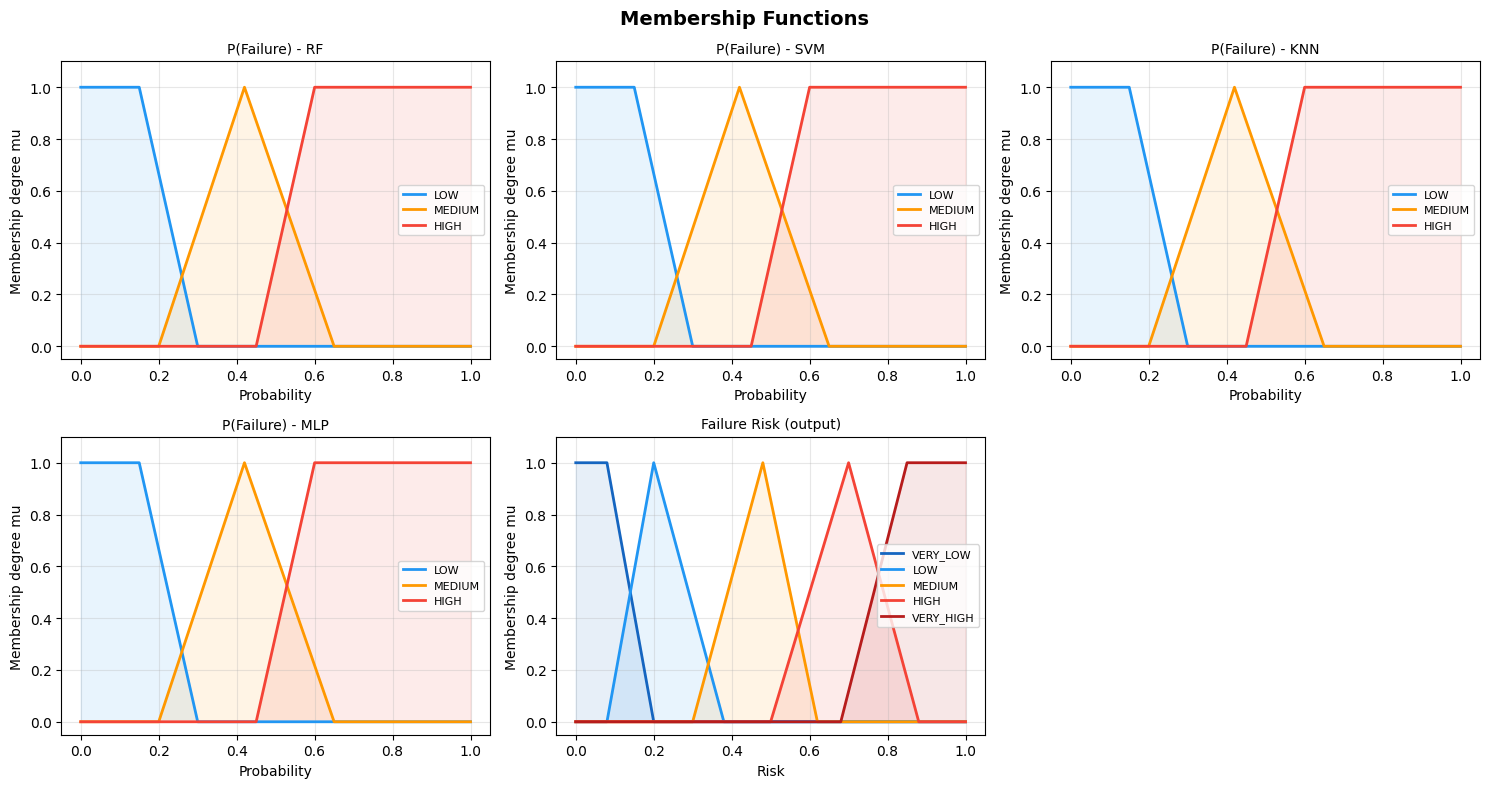

In [85]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Membership Functions', fontsize=14, fontweight='bold')

colors = {'LOW': '#2196F3', 'MEDIUM': '#FF9800', 'HIGH': '#F44336'}
out_colors = {'VERY_LOW': '#1565C0', 'LOW': '#2196F3', 'MEDIUM': '#FF9800',
              'HIGH': '#F44336', 'VERY_HIGH': '#B71C1C'}

input_vars = [
    (p_rf_var,  'P(Failure) - RF'),
    (p_svm_var, 'P(Failure) - SVM'),
    (p_knn_var, 'P(Failure) - KNN'),
    (p_mlp_var, 'P(Failure) - MLP'),
]

ax_flat = axes.flat
for (var, title), ax in zip(input_vars, ax_flat):
    for term, col in colors.items():
        ax.plot(u, var[term].mf, lw=2, label=term, color=col)
        ax.fill_between(u, var[term].mf, alpha=0.1, color=col)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Probability')
    ax.set_ylabel('Membership degree mu')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(-0.05, 1.1)

flat_axes = axes.flatten()
ax_out = flat_axes[4]
for term, col in out_colors.items():
    ax_out.plot(u, risk_var[term].mf, lw=2, label=term, color=col)
    ax_out.fill_between(u, risk_var[term].mf, alpha=0.1, color=col)
ax_out.set_title('Failure Risk (output)', fontsize=10)
ax_out.set_xlabel('Risk')
ax_out.set_ylabel('Membership degree mu')
ax_out.legend(fontsize=8)
ax_out.grid(True, alpha=0.3)
ax_out.set_ylim(-0.05, 1.1)

flat_axes[5].axis('off')
plt.tight_layout()
plt.show()


---
## 3. Mamdani rule base

Rules are divided into three logical groups:

| Group | Description | Conclusion |
|-------|-------------|------------|
| **Consensus HIGH** | All / most models agree on high risk | VERY_HIGH / HIGH |
| **Consensus LOW** | All / most models indicate low risk | VERY_LOW / LOW |
| **Mixed** | Models disagree - ambiguous situation | MEDIUM |

In [86]:
rf  = p_rf_var
svm = p_svm_var
knn = p_knn_var
mlp = p_mlp_var
R   = risk_var

rules = [
    # Dominant rule: MLP HIGH => VERY_HIGH
    ctrl.Rule(mlp['HIGH'], R['VERY_HIGH'],
              label='R00_mlp_dominant'),

    # Full consensus HIGH
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & knn['HIGH'] & mlp['HIGH'],
        R['VERY_HIGH'], label='R01_all_high'),

    # Three of four HIGH
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & knn['HIGH'] & mlp['MEDIUM'],
        R['VERY_HIGH'], label='R02_3high_mlp_med'),
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & mlp['HIGH'] & knn['MEDIUM'],
        R['VERY_HIGH'], label='R03_3high_knn_med'),
    ctrl.Rule(
        rf['HIGH'] & knn['HIGH'] & mlp['HIGH'] & svm['MEDIUM'],
        R['VERY_HIGH'], label='R04_3high_svm_med'),
    ctrl.Rule(
        svm['HIGH'] & knn['HIGH'] & mlp['HIGH'] & rf['MEDIUM'],
        R['VERY_HIGH'], label='R05_3high_rf_med'),

    # Two HIGH + two MEDIUM
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['HIGH'], label='R06_rf_svm_high'),
    ctrl.Rule(
        rf['HIGH'] & mlp['HIGH'] & svm['MEDIUM'] & knn['MEDIUM'],
        R['HIGH'], label='R07_rf_mlp_high'),
    ctrl.Rule(
        knn['HIGH'] & mlp['HIGH'] & rf['MEDIUM'] & svm['MEDIUM'],
        R['HIGH'], label='R08_knn_mlp_high'),
    ctrl.Rule(
        svm['HIGH'] & knn['HIGH'] & rf['MEDIUM'] & mlp['MEDIUM'],
        R['HIGH'], label='R09_svm_knn_high'),

    # One HIGH + rest MEDIUM => HIGH
    ctrl.Rule(
        rf['HIGH'] & svm['MEDIUM'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['HIGH'], label='R10_only_rf_high'),
    ctrl.Rule(
        svm['HIGH'] & rf['MEDIUM'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['HIGH'], label='R11_only_svm_high'),
    ctrl.Rule(
        knn['HIGH'] & rf['MEDIUM'] & svm['MEDIUM'] & mlp['MEDIUM'],
        R['HIGH'], label='R12_only_knn_high'),
    ctrl.Rule(
        mlp['HIGH'] & rf['MEDIUM'] & svm['MEDIUM'] & knn['MEDIUM'],
        R['HIGH'], label='R13_only_mlp_high'),

    # Conflicts HIGH vs LOW => HIGH
    ctrl.Rule(
        rf['HIGH'] & svm['LOW'],
        R['HIGH'], label='R14_rf_high_svm_low'),
    ctrl.Rule(
        knn['HIGH'] & mlp['LOW'],
        R['HIGH'], label='R15_knn_high_mlp_low'),
    ctrl.Rule(
        mlp['HIGH'] & rf['LOW'],
        R['HIGH'], label='R16_mlp_high_rf_low'),
    ctrl.Rule(
        svm['HIGH'] & knn['LOW'],
        R['HIGH'], label='R17_svm_high_knn_low'),

    # Two MEDIUM + two LOW => MEDIUM
    ctrl.Rule(
        rf['MEDIUM'] & svm['MEDIUM'] & knn['LOW'] & mlp['LOW'],
        R['MEDIUM'], label='R18b_rf_svm_med_low'),
    ctrl.Rule(
        knn['MEDIUM'] & mlp['MEDIUM'] & rf['LOW'] & svm['LOW'],
        R['MEDIUM'], label='R18c_knn_mlp_med_low'),

    # Full consensus MEDIUM
    ctrl.Rule(
        rf['MEDIUM'] & svm['MEDIUM'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['MEDIUM'], label='R18_all_medium'),

    # Three HIGH + one LOW => HIGH
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & knn['HIGH'] & mlp['LOW'],
        R['HIGH'], label='R19b_3high_1low'),

    # Two HIGH + two LOW: RF+MLP => HIGH, others => MEDIUM
    ctrl.Rule(
        rf['HIGH'] & mlp['HIGH'] & svm['LOW'] & knn['LOW'],
        R['HIGH'], label='R19c_rf_mlp_high_rest_low'),
    ctrl.Rule(
        rf['HIGH'] & svm['HIGH'] & knn['LOW'] & mlp['LOW'],
        R['MEDIUM'], label='R19_rf_svm_high_knn_mlp_low'),
    ctrl.Rule(
        knn['HIGH'] & mlp['HIGH'] & rf['LOW'] & svm['LOW'],
        R['MEDIUM'], label='R20_knn_mlp_high_rf_svm_low'),

    # One HIGH + one MEDIUM (rest LOW) => MEDIUM
    ctrl.Rule(
        mlp['HIGH'] & rf['MEDIUM'] & svm['LOW'] & knn['LOW'],
        R['MEDIUM'], label='R20b_mlp_high_partial'),
    ctrl.Rule(
        rf['HIGH'] & mlp['MEDIUM'] & svm['LOW'] & knn['LOW'],
        R['MEDIUM'], label='R20c_rf_high_partial'),

    # Full consensus LOW
    ctrl.Rule(
        rf['LOW'] & svm['LOW'] & knn['LOW'] & mlp['LOW'],
        R['VERY_LOW'], label='R21_all_low'),

    # Three of four LOW
    ctrl.Rule(
        rf['LOW'] & svm['LOW'] & knn['LOW'] & mlp['MEDIUM'],
        R['LOW'], label='R22_3low_mlp_med'),
    ctrl.Rule(
        rf['LOW'] & svm['LOW'] & mlp['LOW'] & knn['MEDIUM'],
        R['LOW'], label='R23_3low_knn_med'),
    ctrl.Rule(
        rf['LOW'] & knn['LOW'] & mlp['LOW'] & svm['MEDIUM'],
        R['LOW'], label='R24_3low_svm_med'),
    ctrl.Rule(
        svm['LOW'] & knn['LOW'] & mlp['LOW'] & rf['MEDIUM'],
        R['LOW'], label='R25_3low_rf_med'),

    # Two LOW + two MEDIUM
    ctrl.Rule(
        rf['LOW'] & svm['LOW'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['LOW'], label='R26_rf_svm_low'),
    ctrl.Rule(
        knn['LOW'] & mlp['LOW'] & rf['MEDIUM'] & svm['MEDIUM'],
        R['LOW'], label='R27_knn_mlp_low'),

    # One LOW + rest MEDIUM
    ctrl.Rule(
        rf['LOW'] & svm['MEDIUM'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['LOW'], label='R28_only_rf_low'),
    ctrl.Rule(
        svm['LOW'] & rf['MEDIUM'] & knn['MEDIUM'] & mlp['MEDIUM'],
        R['LOW'], label='R29_only_svm_low'),
    ctrl.Rule(
        knn['LOW'] & rf['MEDIUM'] & svm['MEDIUM'] & mlp['MEDIUM'],
        R['LOW'], label='R30_only_knn_low'),
    ctrl.Rule(
        mlp['LOW'] & rf['MEDIUM'] & svm['MEDIUM'] & knn['MEDIUM'],
        R['LOW'], label='R31_only_mlp_low'),
]

print(f'Rule base defined: {len(rules)} rules (HIGH-RECALL mode).')

Rule base defined: 38 rules (HIGH-RECALL mode).


---
## 4. Control system build and compilation

In [87]:
failure_ctrl = ctrl.ControlSystem(rules)
failure_sim  = ctrl.ControlSystemSimulation(failure_ctrl)

print(f'Number of rules: {len(rules)}')
print(f'Number of inputs: {len(list(failure_ctrl.antecedents))}')
print(f'Number of outputs: {len(list(failure_ctrl.consequents))}')
print(f'Defuzzification method: centroid')

Number of rules: 38
Number of inputs: 4
Number of outputs: 1
Defuzzification method: centroid


---
## 5. Prediction on the test set


In [88]:
def fuzzy_predict(p_rf_val, p_svm_val, p_knn_val, p_mlp_val, sim):
    sim.input['p_rf']  = float(np.clip(p_rf_val,  0.001, 0.999))
    sim.input['p_svm'] = float(np.clip(p_svm_val, 0.001, 0.999))
    sim.input['p_knn'] = float(np.clip(p_knn_val, 0.001, 0.999))
    sim.input['p_mlp'] = float(np.clip(p_mlp_val, 0.001, 0.999))
    sim.compute()
    return sim.output['failure_risk']

fuzzy_scores = []
errors = 0

for i in range(n):
    try:
        score = fuzzy_predict(p_rf[i], p_svm[i], p_knn[i], p_mlp[i], failure_sim)
        fuzzy_scores.append(score)
    except Exception:
        fallback = 0.35*p_rf[i] + 0.25*p_svm[i] + 0.20*p_knn[i] + 0.20*p_mlp[i]
        fuzzy_scores.append(fallback)
        errors += 1

fuzzy_scores = np.array(fuzzy_scores)

print(f'Score range: [{fuzzy_scores.min():.4f}, {fuzzy_scores.max():.4f}]')
print(f'Mean: {fuzzy_scores.mean():.4f}')
print(f'Std dev: {fuzzy_scores.std():.4f}')


Score range: [0.0743, 0.8774]
Mean: 0.1457
Std dev: 0.1999


---
## 6. Binarisation and quality evaluation

In [89]:
from sklearn.metrics import f1_score, recall_score, precision_score

# minimum acceptable Precision
MIN_PRECISION = 0.30

thresholds = np.linspace(0.05, 0.95, 181)

recall_scores    = []
precision_scores = []
f1_scores        = []

for t in thresholds:
    pred = (fuzzy_scores >= t).astype(int)
    if pred.sum() == 0:
        recall_scores.append(0.0)
        precision_scores.append(0.0)
        f1_scores.append(0.0)
    else:
        recall_scores.append(recall_score(y_true, pred, zero_division=0))
        precision_scores.append(precision_score(y_true, pred, zero_division=0))
        f1_scores.append(f1_score(y_true, pred, zero_division=0))

recall_scores    = np.array(recall_scores)
precision_scores = np.array(precision_scores)
f1_scores        = np.array(f1_scores)

valid_mask = precision_scores >= MIN_PRECISION
if valid_mask.any():
    best_thresh = thresholds[valid_mask][np.argmax(recall_scores[valid_mask])]
    strategy = f'max Recall with Precision >= {MIN_PRECISION:.0%}'
else:
    best_thresh = thresholds[np.argmax(recall_scores)]
    strategy = 'unconditional max Recall (no Precision constraint satisfied)'


print(f'Threshold strategy: {strategy}')
print(f'Optimal threshold (Recall): {best_thresh:.2f}')

fuzzy_pred = (fuzzy_scores >= best_thresh).astype(int)

roc_auc  = roc_auc_score(y_true, fuzzy_scores)
avg_prec = average_precision_score(y_true, fuzzy_scores)

print('\n- Classification report - Mamdani System -')
print(classification_report(y_true, fuzzy_pred, target_names=['No Failure', 'Failure']))
print(f'ROC-AUC: {roc_auc:.4f}')
print(f'Average Precision: {avg_prec:.4f}')

print('\n- ROC-AUC comparison -')
models_auc = {
    'RF': rf_art['roc_auc'],
    'SVM': svm_art['roc_auc'],
    'KNN': knn_art['roc_auc'],
    'MLP': mlp_art['roc_auc'],
    'Mamdani': roc_auc,
}
for name, auc in models_auc.items():
    print(f'  {name:8s}: {auc:.4f}')

Threshold strategy: max Recall with Precision >= 30%
Optimal threshold (Recall): 0.22

- Classification report - Mamdani System -
              precision    recall  f1-score   support

  No Failure       1.00      0.94      0.97      1449
     Failure       0.34      0.94      0.50        51

    accuracy                           0.94      1500
   macro avg       0.67      0.94      0.73      1500
weighted avg       0.98      0.94      0.95      1500

ROC-AUC: 0.9729
Average Precision: 0.6879

- ROC-AUC comparison -
  RF      : 0.9614
  SVM     : 0.9655
  KNN     : 0.9534
  MLP     : 0.9799
  Mamdani : 0.9729


---
## 7. Results visualisation

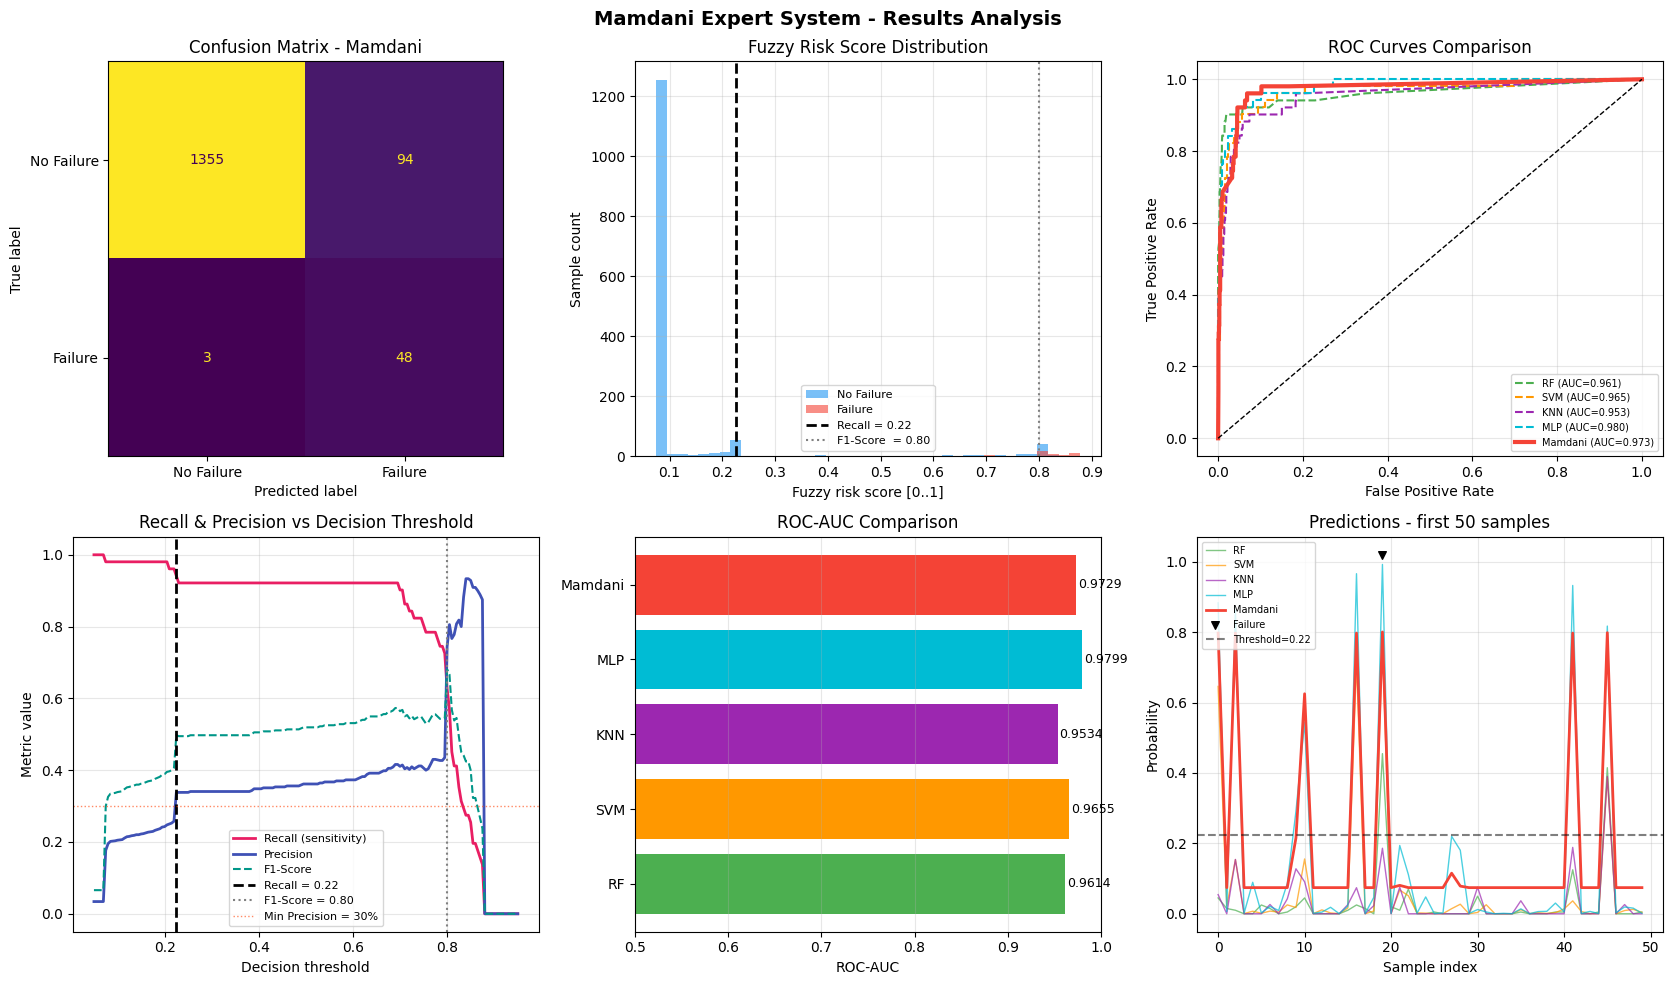

In [90]:
from sklearn.metrics import roc_curve, precision_recall_curve

best_thresh_f1 = thresholds[np.argmax(f1_scores)]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle('Mamdani Expert System - Results Analysis', fontsize=14, fontweight='bold')

ax = axes[0, 0]
cm = confusion_matrix(y_true, fuzzy_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No Failure', 'Failure'])
disp.plot(ax=ax, colorbar=False)
ax.set_title('Confusion Matrix - Mamdani')

ax = axes[0, 1]
ax.hist(fuzzy_scores[y_true == 0], bins=40, alpha=0.6, color='#2196F3', label='No Failure')
ax.hist(fuzzy_scores[y_true == 1], bins=40, alpha=0.6, color='#F44336', label='Failure')
ax.axvline(best_thresh,    color='black', lw=2, ls='--', label=f'Recall = {best_thresh:.2f}')
ax.axvline(best_thresh_f1, color='gray',  lw=1.5, ls=':', label=f'F1-Score  = {best_thresh_f1:.2f}')
ax.set_xlabel('Fuzzy risk score [0..1]')
ax.set_ylabel('Sample count')
ax.set_title('Fuzzy Risk Score Distribution')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[0, 2]
model_probas = {
    'RF': (p_rf,  rf_art['roc_auc'],  '#4CAF50'),
    'SVM': (p_svm, svm_art['roc_auc'], '#FF9800'),
    'KNN': (p_knn, knn_art['roc_auc'], '#9C27B0'),
    'MLP': (p_mlp, mlp_art['roc_auc'],  '#00BCD4'),
    'Mamdani': (fuzzy_scores, roc_auc,     '#F44336'),
}
for name, (proba, auc, col) in model_probas.items():
    fpr, tpr, _ = roc_curve(y_true, proba)
    lw = 3 if name == 'Mamdani' else 1.5
    ls = '-' if name == 'Mamdani' else '--'
    ax.plot(fpr, tpr, lw=lw, ls=ls, color=col, label=f'{name} (AUC={auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves Comparison')
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
ax.plot(thresholds, recall_scores, lw=2, color='#E91E63', label='Recall (sensitivity)')
ax.plot(thresholds, precision_scores, lw=2, color='#3F51B5', label='Precision')
ax.plot(thresholds, f1_scores, lw=1.5, color='#009688', ls='--', label='F1-Score')
ax.axvline(best_thresh, color='black', lw=2, ls='--',  label=f'Recall = {best_thresh:.2f}')
ax.axvline(best_thresh_f1, color='gray',  lw=1.5, ls=':', label=f'F1-Score = {best_thresh_f1:.2f}')
ax.axhline(MIN_PRECISION, color='#FF5722', lw=1, ls=':', alpha=0.7, label=f'Min Precision = {MIN_PRECISION:.0%}')
ax.set_xlabel('Decision threshold')
ax.set_ylabel('Metric value')
ax.set_title('Recall & Precision vs Decision Threshold')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1, 1]
names = list(models_auc.keys())
aucs  = list(models_auc.values())
bar_colors = ['#4CAF50', '#FF9800', '#9C27B0', '#00BCD4', '#F44336']
bars = ax.barh(names, aucs, color=bar_colors)
ax.set_xlabel('ROC-AUC')
ax.set_title('ROC-AUC Comparison')
ax.set_xlim(0.5, 1.0)
for bar, val in zip(bars, aucs):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9)
ax.grid(True, alpha=0.3, axis='x')

ax = axes[1, 2]
idx50 = np.arange(50)
ax.plot(idx50, p_rf[:50], lw=1, alpha=0.7, color='#4CAF50', label='RF')
ax.plot(idx50, p_svm[:50], lw=1, alpha=0.7, color='#FF9800', label='SVM')
ax.plot(idx50, p_knn[:50], lw=1, alpha=0.7, color='#9C27B0', label='KNN')
ax.plot(idx50, p_mlp[:50], lw=1, alpha=0.7, color='#00BCD4', label='MLP')
ax.plot(idx50, fuzzy_scores[:50], lw=2, color='#F44336', label='Mamdani')
ax.scatter(idx50[y_true[:50]==1],
           np.ones(y_true[:50].sum()) * 1.02,
           marker='v', color='black', s=30, label='Failure')
ax.axhline(best_thresh, color='black', lw=1.5, ls='--', alpha=0.5, label=f'Threshold={best_thresh:.2f}')
ax.set_xlabel('Sample index')
ax.set_ylabel('Probability')
ax.set_title('Predictions - first 50 samples')
ax.legend(fontsize=7, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---
## 8. Inference demonstration - example scenarios

In [91]:
from tabulate import tabulate

scenarios = [
    {'name': 'Full consensus HIGH',
     'rf': 0.90, 'svm': 0.88, 'knn': 0.85, 'mlp': 0.92},
    {'name': 'Full consensus LOW',
     'rf': 0.05, 'svm': 0.08, 'knn': 0.06, 'mlp': 0.04},
    {'name': 'Full consensus MEDIUM',
     'rf': 0.50, 'svm': 0.50, 'knn': 0.50, 'mlp': 0.50},
    {'name': 'Conflict RF high vs SVM low',
     'rf': 0.85, 'svm': 0.12, 'knn': 0.50, 'mlp': 0.55},
    {'name': 'RF+SVM HIGH, KNN+MLP LOW',
     'rf': 0.80, 'svm': 0.82, 'knn': 0.10, 'mlp': 0.08},
    {'name': 'Borderline decision',
     'rf': 0.55, 'svm': 0.48, 'knn': 0.52, 'mlp': 0.49},
]

table_data = []
for sc in scenarios:
    risk = fuzzy_predict(sc['rf'], sc['svm'], sc['knn'], sc['mlp'], failure_sim)
    decision = 'FAILURE' if risk >= best_thresh else 'OK'
    table_data.append([
        sc['name'],
        f"{sc['rf']:.2f}",
        f"{sc['svm']:.2f}",
        f"{sc['knn']:.2f}",
        f"{sc['mlp']:.2f}",
        f"{risk:.4f}",
        decision
    ])

headers = ['Scenario', 'RF', 'SVM', 'KNN', 'MLP', 'Mamdani Output', 'Decision']

print(tabulate(table_data, headers=headers, tablefmt='grid', stralign='center', numalign='center'))

+-----------------------------+------+-------+-------+-------+------------------+------------+
|          Scenario           |  RF  |  SVM  |  KNN  |  MLP  |  Mamdani Output  |  Decision  |
+=============================+======+=======+=======+=======+==================+============+
|     Full consensus HIGH     | 0.9  | 0.88  | 0.85  | 0.92  |      0.8774      |  FAILURE   |
+-----------------------------+------+-------+-------+-------+------------------+------------+
|     Full consensus LOW      | 0.05 | 0.08  | 0.06  | 0.04  |      0.0743      |     OK     |
+-----------------------------+------+-------+-------+-------+------------------+------------+
|    Full consensus MEDIUM    | 0.5  |  0.5  |  0.5  |  0.5  |      0.628       |  FAILURE   |
+-----------------------------+------+-------+-------+-------+------------------+------------+
| Conflict RF high vs SVM low | 0.85 | 0.12  |  0.5  | 0.55  |      0.7759      |  FAILURE   |
+-----------------------------+------+-------+----

---
## 9. Sensitivity analysis

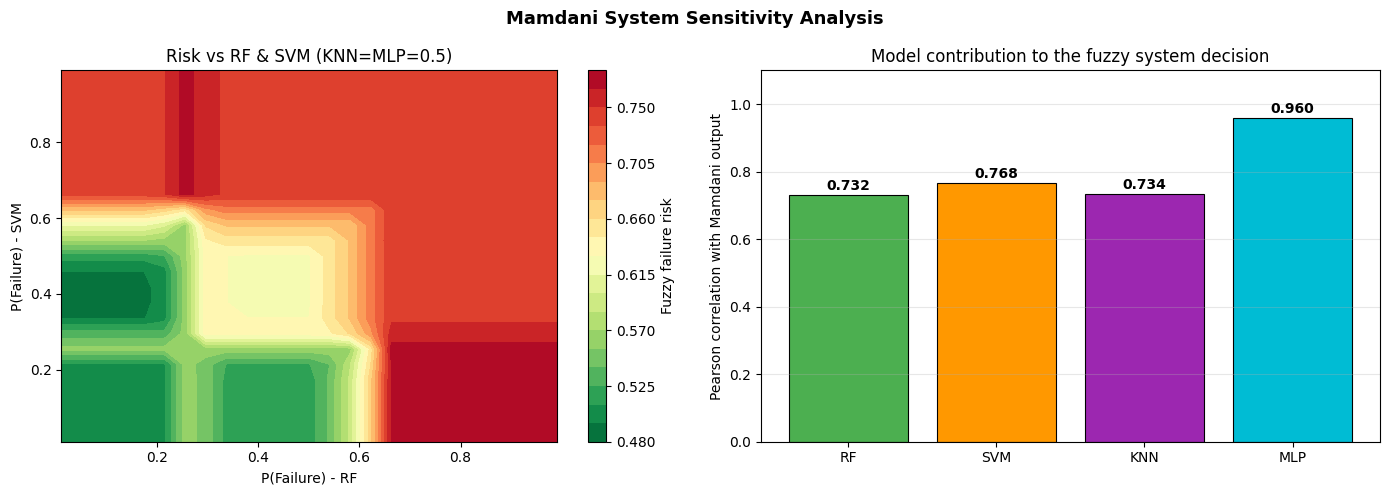

In [95]:
grid_vals  = np.linspace(0.01, 0.99, 25)
risk_grid  = np.zeros((len(grid_vals), len(grid_vals)))

for i, v_rf in enumerate(grid_vals):
    for j, v_svm in enumerate(grid_vals):
        try:
            risk_grid[i, j] = fuzzy_predict(v_rf, v_svm, 0.5, 0.5, failure_sim)
        except Exception:
            risk_grid[i, j] = 0.5 * (v_rf + v_svm) / 2 + 0.25

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Mamdani System Sensitivity Analysis', fontsize=13, fontweight='bold')

ax = axes[0]
im = ax.contourf(grid_vals, grid_vals, risk_grid, levels=20, cmap='RdYlGn_r')
fig.colorbar(im, ax=ax, label='Fuzzy failure risk')
ax.contour(grid_vals, grid_vals, risk_grid, levels=[best_thresh],
           colors='black', linewidths=2)
ax.set_xlabel('P(Failure) - RF')
ax.set_ylabel('P(Failure) - SVM')
ax.set_title('Risk vs RF & SVM (KNN=MLP=0.5)')

ax = axes[1]
model_names = ['RF', 'SVM', 'KNN', 'MLP']
model_probs = [p_rf, p_svm, p_knn, p_mlp]
correlations = [np.corrcoef(p, fuzzy_scores)[0, 1] for p in model_probs]
bar_cols = ['#4CAF50', '#FF9800', '#9C27B0', '#00BCD4']
bars = ax.bar(model_names, correlations, color=bar_cols, edgecolor='black', linewidth=0.8)
for bar, val in zip(bars, correlations):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.005,
            f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_ylabel('Pearson correlation with Mamdani output')
ax.set_title('Model contribution to the fuzzy system decision')
ax.set_ylim(0, 1.1)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


---
## 10. Summary


In [94]:
from sklearn.metrics import f1_score, precision_score, recall_score


print('- Summary - Mamdani Expert System -')
print(f'Test samples: {n}')
print(f'Optimal threshold (Recall): {best_thresh:.2f}')
print(f'Optimal threshold (F1): {best_thresh_f1:.2f}  (for comparison)')
print(f'Min. Precision: {MIN_PRECISION:.0%}')
print(f'Defuzzification method: centroid')
print(f'Rules in knowledge base: {len(rules)}')
print()

p  = precision_score(y_true, fuzzy_pred)
r  = recall_score(y_true, fuzzy_pred)
f1 = f1_score(y_true, fuzzy_pred)

fuzzy_pred_f1 = (fuzzy_scores >= best_thresh_f1).astype(int)
p_f1  = precision_score(y_true, fuzzy_pred_f1)
r_f1  = recall_score(y_true, fuzzy_pred_f1)
f1_f1 = f1_score(y_true, fuzzy_pred_f1)

print(f'{"Metric":<28} {"Recall thr":>12} {"F1 thr":>12}')
print(f'{"-"*54}')
print(f'{"ROC-AUC":<28} {roc_auc:>12.4f} {roc_auc:>12.4f}')
print(f'{"Average Precision":<28} {avg_prec:>12.4f} {avg_prec:>12.4f}')
print(f'{"Precision (Failure)":<28} {p:>12.4f} {p_f1:>12.4f}')
print(f'{"Recall (Failure)":<28} {r:>12.4f} {r_f1:>12.4f}')
print(f'{"F1-Score (Failure)":<28} {f1:>12.4f} {f1_f1:>12.4f}')
print()


- Summary - Mamdani Expert System -
Test samples: 1500
Optimal threshold (Recall): 0.22
Optimal threshold (F1): 0.80  (for comparison)
Min. Precision: 30%
Defuzzification method: centroid
Rules in knowledge base: 38

Metric                         Recall thr       F1 thr
------------------------------------------------------
ROC-AUC                            0.9729       0.9729
Average Precision                  0.6879       0.6879
Precision (Failure)                0.3380       0.7442
Recall (Failure)                   0.9412       0.6275
F1-Score (Failure)                 0.4974       0.6809

